# 02 Exploratory analysis
Questions: how strong is home advantage, how many goals, how does Elo relate to results?

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import warnings; warnings.filterwarnings('ignore')
import pandas as pd, matplotlib.pyplot as plt, config
from src import data_processing as dp
m = dp.load(); p = m[m['played']]
figs = config.FIGURES_DIR; figs.mkdir(parents=True, exist_ok=True)

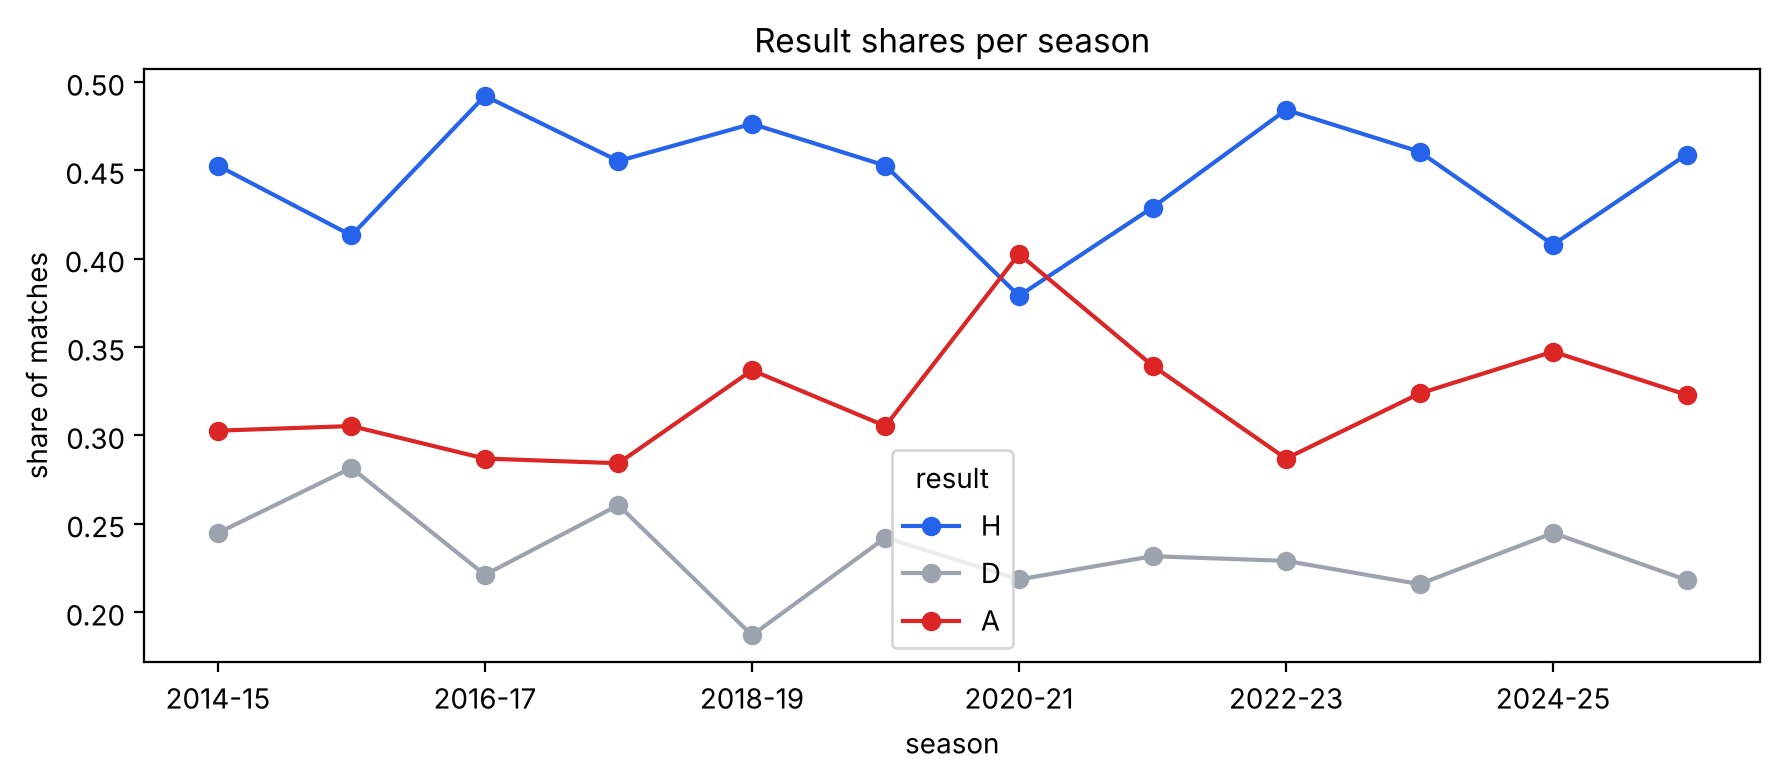

result,H,D,A
season,,,
2014-15,0.453,0.245,0.303
2015-16,0.413,0.282,0.305
2016-17,0.492,0.221,0.287
2017-18,0.455,0.261,0.284
2018-19,0.476,0.187,0.337
2019-20,0.453,0.242,0.305
2020-21,0.379,0.218,0.403
2021-22,0.429,0.232,0.339
2022-23,0.484,0.229,0.287


In [2]:
share = p.groupby('season')['result'].value_counts(normalize=True).unstack()[['H','D','A']]
ax = share.plot(marker='o', figsize=(9,4), color=['#2563eb','#9ca3af','#dc2626']); ax.set_ylabel('share of matches'); ax.set_title('Result shares per season')
plt.tight_layout(); plt.savefig(figs/'result_share_by_season.png', dpi=130); plt.show()
share.round(3)

Home wins are the most common result in every season. The 2020-21 season (empty stadiums) shows the smallest home advantage.

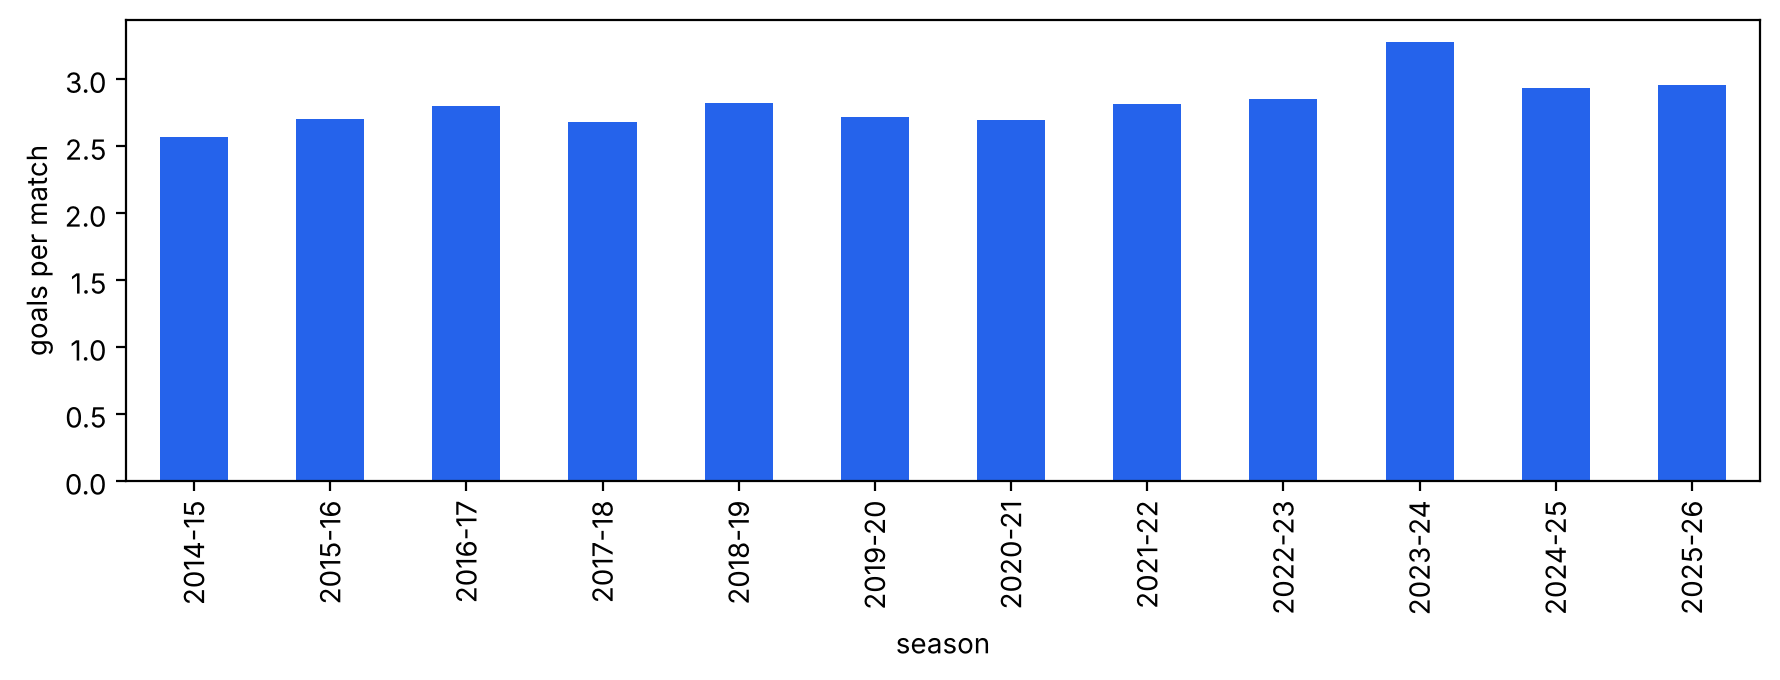

In [3]:
g = (p['home_goals']+p['away_goals']).groupby(p['season']).mean()
ax = g.plot.bar(figsize=(9,3.5), color='#2563eb'); ax.set_ylabel('goals per match')
plt.tight_layout(); plt.savefig(figs/'goals_per_match.png', dpi=130); plt.show()

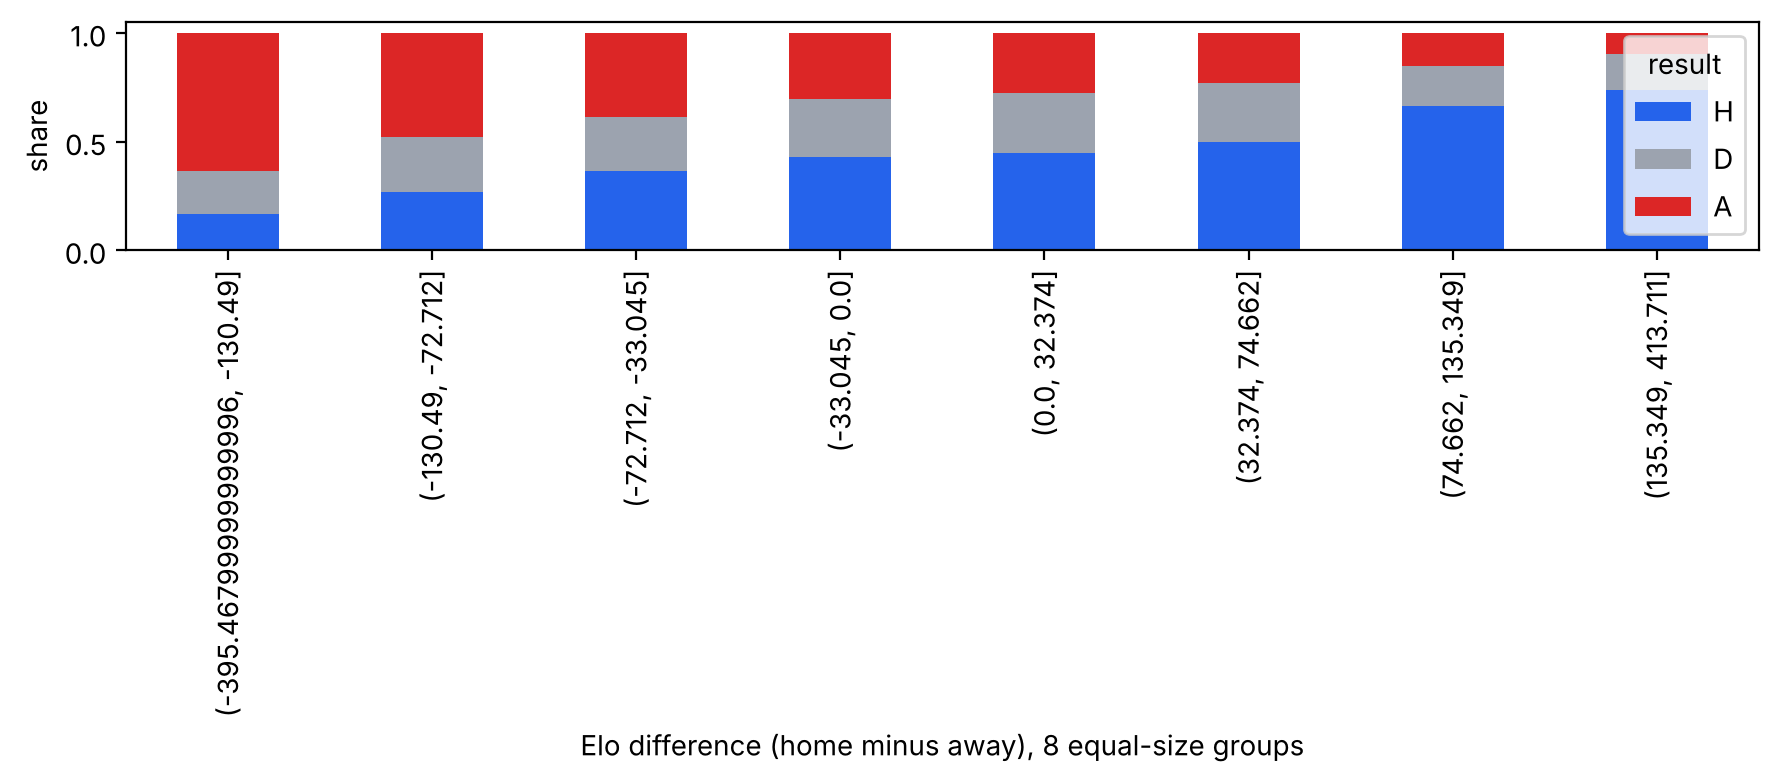

result,H,D,A
bin,,,
"(-395.46799999999996, -130.49]",0.166,0.198,0.637
"(-130.49, -72.712]",0.270,0.250,0.480
"(-72.712, -33.045]",0.362,0.253,0.385
"(-33.045, 0.0]",0.428,0.268,0.305
"(0.0, 32.374]",0.448,0.274,0.278
"(32.374, 74.662]",0.499,0.270,0.231
"(74.662, 135.349]",0.663,0.186,0.152
"(135.349, 413.711]",0.739,0.166,0.095


In [4]:
f = pd.read_csv(config.FEATURES_FILE).dropna(subset=['elo_diff'])
f['bin'] = pd.qcut(f['elo_diff'], 8)
t = f.groupby('bin', observed=True)['result'].value_counts(normalize=True).unstack()[['H','D','A']]
ax = t.plot.bar(stacked=True, figsize=(9,4), color=['#2563eb','#9ca3af','#dc2626']); ax.set_xlabel('Elo difference (home minus away), 8 equal-size groups'); ax.set_ylabel('share')
plt.tight_layout(); plt.savefig(figs/'result_by_elo_diff.png', dpi=130); plt.show()
t.round(3)

The bigger the Elo advantage of the home club, the more home wins and the fewer away wins. Draws are most common between evenly matched clubs (about 27%) and rarer at the extremes (17-20%), but never more likely than the best alternative, which is why draws are hard to predict.